Carregamento dos dados e importação de bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import (KNeighborsClassifier)
from sklearn.naive_bayes import (GaussianNB)
from sklearn.model_selection import (cross_val_score)
from sklearn.model_selection import (StratifiedKFold)
from sklearn.preprocessing import(MinMaxScaler)

# Load the breast cancer dataset
def load_breast_cancer_data(filepath='breast.w.arff'):
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    
    # Decode class labels
    df['Class'] = df['Class'].apply(lambda x: x.decode('utf-8'))
    
    return df, meta

# Load data
df, meta = load_breast_cancer_data('breast.w.arff')

# Prepare data
X = df.drop('Class', axis=1).values
y = df['Class'].values

Exercício 1

a)

In [144]:
stratifiedKfold = StratifiedKFold(5,shuffle=True, random_state=0)
kNN = KNeighborsClassifier(n_neighbors=5)
naiiveBG = GaussianNB()

accuracy_kNN = cross_val_score(kNN, X, y, cv = stratifiedKfold, scoring= 'accuracy')
accuracy_naiiveBG = cross_val_score(naiiveBG, X, y, cv = stratifiedKfold, scoring = 'accuracy')

print("Accuracy kNN:", accuracy_kNN)
print("Desvio padrão kNN:", accuracy_kNN.std())
print("Média kNN:", accuracy_kNN.mean())
print("Accuracy naiive bayes:", accuracy_naiiveBG)
print("Desvio padrão naiive bayes:", accuracy_naiiveBG.std())
print("Média naiive bayes:", accuracy_naiiveBG.mean())

Accuracy kNN: [0.99270073 0.96350365 0.96350365 0.94117647 0.98529412]
Desvio padrão kNN: 0.018229172031416895
Média kNN: 0.9692357234864749
Accuracy naiive bayes: [0.98540146 0.94890511 0.94890511 0.95588235 0.97058824]
Desvio padrão naiive bayes: 0.014154461052591927
Média naiive bayes: 0.9619364534134822


b)

In [148]:
stratifiedKfold = StratifiedKFold(5,shuffle=True, random_state=0)
scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(X)
accuracy_kNN_minmax = cross_val_score(kNN, x_scaled, y, cv = stratifiedKfold, scoring = 'accuracy')

print("Accuracy kNN with preprocessing the data with a Min-Max scaler:", accuracy_kNN_minmax)
print("Desvio Padrão:", accuracy_kNN_minmax.std())
print("Média:", accuracy_kNN_minmax.mean())

Accuracy kNN with preprocessing the data with a Min-Max scaler: [0.99270073 0.96350365 0.96350365 0.94117647 0.97794118]
Desvio Padrão: 0.017138338919556715
Média: 0.9677651352511807


c)


In [151]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
stratifiedKfold = StratifiedKFold(5, shuffle=True, random_state=0)

kNN = KNeighborsClassifier(n_neighbors=5)
naiiveBG = GaussianNB()

acc_kNN = cross_val_score(kNN, X_scaled, y, cv=stratifiedKfold, scoring="accuracy")
acc_NB  = cross_val_score(naiiveBG, X_scaled, y, cv=stratifiedKfold, scoring="accuracy")

print("Acurácias kNN escalado:", acc_kNN)
print("Acurácias Naive Bayes escalado:", acc_NB)

t_stat, p_val = stats.ttest_rel(acc_kNN, acc_NB)

print("Teste t-> t:", t_stat, "p:", p_val)
print("Média kNN:", acc_kNN.mean())
print("Média NB:", acc_NB.mean())

if p_val < 0.05:
    if acc_kNN.mean() > acc_NB.mean():
        print("Conclusão: kNN escalado é estatisticamente superior ao Naiive Bayes escalado.")
    else:
        print("Conclusão: Naiive Bayes escalado é estatisticamente superior ao kNN escalado.")
else:
    print("Conclusão: não há diferença estatisticamente significativa entre os modelos.")

Acurácias kNN escalado: [0.99270073 0.96350365 0.96350365 0.94117647 0.97794118]
Acurácias Naive Bayes escalado: [0.98540146 0.94890511 0.94890511 0.95588235 0.97058824]
Teste t-> t: 1.0823822303350672 p: 0.3399717747301736
Média kNN: 0.9677651352511807
Média NB: 0.9619364534134822
Conclusão: não há diferença estatisticamente significativa entre os modelos.


Exercício 2

a)

training_accuracies_uni:  [1.0, 0.9853556485355649, 0.9748953974895398, 0.9728033472803347, 0.9665271966527197, 0.9686192468619247]
testing_accuracies_uni:  [0.9512195121951219, 0.9658536585365853, 0.9658536585365853, 0.9707317073170731, 0.9560975609756097, 0.9512195121951219]
training_accuracies_dis:  [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
testing_accuracies_dis:  [0.9512195121951219, 0.9658536585365853, 0.9609756097560975, 0.9658536585365853, 0.9609756097560975, 0.9560975609756097]


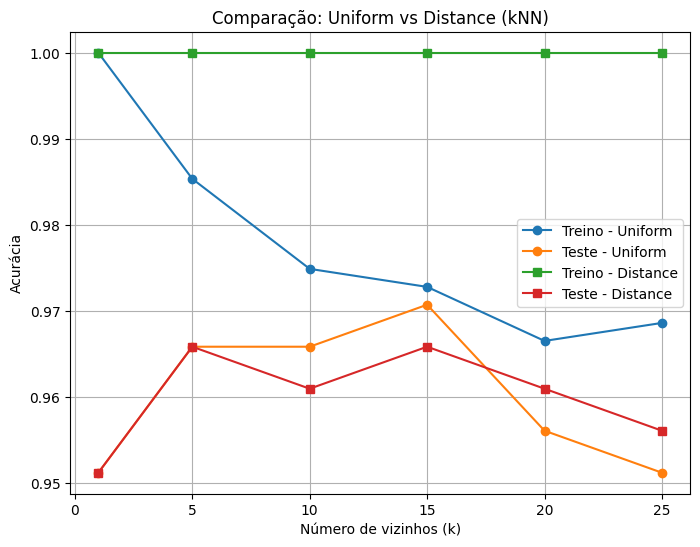

In [153]:
ks = [1,5,10,15,20,25]

training_accuracies_uni = []
testing_accuracies_uni = []

training_accuracies_dis = []
testing_accuracies_dis = []

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

for k in ks:
    kNNC_uni = KNeighborsClassifier(n_neighbors=k, weights= 'uniform')
    kNNC_uni.fit(X_train, y_train)
 
    y_train_predicted_uni = kNNC_uni.predict(X_train)
    y_test_predicted_uni = kNNC_uni.predict(X_test)

    training_accuracies_uni.append(accuracy_score(y_train, y_train_predicted_uni))
    testing_accuracies_uni.append(accuracy_score(y_test, y_test_predicted_uni))

    kNNC_dis = KNeighborsClassifier(n_neighbors=k, weights = 'distance')
    kNNC_dis.fit(X_train, y_train)
 
    y_train_predicted_dis = kNNC_dis.predict(X_train)
    y_test_predicted_dis = kNNC_dis.predict(X_test)

    training_accuracies_dis.append(accuracy_score(y_train, y_train_predicted_dis))
    testing_accuracies_dis.append(accuracy_score(y_test, y_test_predicted_dis))

print("training_accuracies_uni: ",training_accuracies_uni)
print("testing_accuracies_uni: ",testing_accuracies_uni)
print("training_accuracies_dis: ",training_accuracies_dis)
print("testing_accuracies_dis: ",testing_accuracies_dis)


plt.figure(figsize=(8,6))
plt.plot(ks, training_accuracies_uni, label="Treino - Uniform", marker='o')
plt.plot(ks, testing_accuracies_uni, label="Teste - Uniform", marker='o')
plt.plot(ks, training_accuracies_dis, label="Treino - Distance", marker='s')
plt.plot(ks, testing_accuracies_dis, label="Teste - Distance", marker='s')

plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia")
plt.title("Comparação: Uniform vs Distance (kNN)")
plt.legend()
plt.grid(True)
plt.show()